# Give Me Some Credit — Credit Scorecard & Model Validation

Mô hình ước tính xác suất khách hàng quá hạn từ 90 ngày trở lên trong vòng hai năm (`SeriousDlqin2yrs`). Quy trình gồm kiểm tra dữ liệu, xây dựng scorecard bằng Logistic Regression, đối chiếu với mô hình cây và đánh giá khả năng phân biệt, độ chính xác của xác suất dự báo và độ ổn định của dữ liệu đầu vào.

## Báo cáo kiểm định độc lập · tóm tắt và findings register

In [1]:
from IPython.display import display, HTML
report_slot = display(HTML('<p>Báo cáo được cập nhật sau khi chạy phần kiểm định.</p>'),display_id=True)

## 1. Đọc dữ liệu từ thư mục dự án

Mở notebook từ thư mục chứa ba file CSV và bảng mô tả biến `Data Dictionary.xls`. Nếu thiếu thư viện đọc tệp XLS, chạy `%pip install xlrd` trong một cell.

In [2]:
# Nếu thiếu thư viện, bỏ dấu # ở dòng sau và chạy một lần:
# %pip install xlrd pandas numpy scikit-learn scipy matplotlib seaborn statsmodels

from threadpoolctl import threadpool_limits
from pathlib import Path
import warnings


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss,
    log_loss, confusion_matrix)
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
_thread_limit = threadpool_limits(limits=2)
sns.set_theme(style='whitegrid', context='notebook')

In [3]:
import os
data_dir = next((d for d in [Path(os.environ.get('GMC_DATA_DIR','.')),Path.cwd(), *Path.cwd().parents, Path(r'D:/Desktop/Give Me Some Credit')] if (d / 'cs-training.csv').exists()), Path.cwd())
train = pd.read_csv(data_dir / 'cs-training.csv').rename(columns={'Unnamed: 0': 'Id'})
test = pd.read_csv(data_dir / 'cs-test.csv').rename(columns={'Unnamed: 0': 'Id'})
sample_submission = pd.read_csv(data_dir / 'sampleEntry.csv')
data_dictionary = pd.read_excel(data_dir / 'Data Dictionary.xls', engine='xlrd')

print(f'Train: {train.shape} | Test: {test.shape}')
display(data_dictionary)
display(train.head())

Train: (150000, 12) | Test: (101503, 12)


,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 2. Data audit

Kiểm tra tỷ lệ khách hàng quá hạn, dữ liệu thiếu, dòng trùng lặp, giá trị bất thường và sự khác biệt về cấu trúc cột giữa hai tập dữ liệu.

In [4]:
TARGET = 'SeriousDlqin2yrs'
ID_COL = 'Id' if 'Id' in train.columns else None
if TARGET not in train.columns:
    raise KeyError(f'Không tìm thấy biến mục tiêu {TARGET}. Các cột hiện có: {train.columns.tolist()}')

feature_cols = [c for c in train.columns if c not in [TARGET, ID_COL]]
print('Tỷ lệ quá hạn:', train[TARGET].mean())
print('Số hồ sơ theo tình trạng quá hạn:')
display(train[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame('Số hồ sơ'))

audit = pd.DataFrame({
    'Dtype': train[feature_cols].dtypes.astype(str),
    'Missing count': train[feature_cols].isna().sum(),
    'Missing rate': train[feature_cols].isna().mean(),
    'Unique values': train[feature_cols].nunique(dropna=False),
    'Min': train[feature_cols].min(numeric_only=True),
    'Max': train[feature_cols].max(numeric_only=True),
}).sort_values('Missing rate', ascending=False)
display(audit)

print('Số dòng trùng lặp:', train.duplicated().sum())
print('Cột chỉ có trong tập train:', sorted(set(train.columns) - set(test.columns)))
print('Cột chỉ có trong tập test:', sorted(set(test.columns) - set(train.columns)))

Tỷ lệ quá hạn: 0.06684
Số hồ sơ theo tình trạng quá hạn:


,Số hồ sơ
SeriousDlqin2yrs,
0,139974
1,10026


,Dtype,Missing count,Missing rate,Unique values,Min,Max
MonthlyIncome,float64,29731,0.198207,13595,0.0,3008750.0
NumberOfDependents,float64,3924,0.026160,14,0.0,20.0
age,int64,0,0.000000,86,0.0,109.0
RevolvingUtilizationOfUnsecuredLines,float64,0,0.000000,125728,0.0,50708.0
DebtRatio,float64,0,0.000000,114194,0.0,329664.0
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.000000,16,0.0,98.0
NumberOfOpenCreditLinesAndLoans,int64,0,0.000000,58,0.0,58.0
NumberOfTimes90DaysLate,int64,0,0.000000,19,0.0,98.0
NumberRealEstateLoansOrLines,int64,0,0.000000,28,0.0,54.0
NumberOfTime60-89DaysPastDueNotWorse,int64,0,0.000000,13,0.0,98.0


Số dòng trùng lặp: 0
Cột chỉ có trong tập train: []
Cột chỉ có trong tập test: []


,Số giá trị âm,Số giá trị bằng 0,Số giá trị vô hạn,p99,p999
RevolvingUtilizationOfUnsecuredLines,0,10878,0,1.092956,1571.006
age,0,1,0,87.000000,94.000
NumberOfTime30-59DaysPastDueNotWorse,0,126018,0,4.000000,98.000
DebtRatio,0,4113,0,4979.040000,10613.074
MonthlyIncome,0,1634,0,25000.000000,78395.748
NumberOfOpenCreditLinesAndLoans,0,1888,0,24.000000,34.000
NumberOfTimes90DaysLate,0,141662,0,3.000000,98.000
NumberRealEstateLoansOrLines,0,56188,0,4.000000,9.000
NumberOfTime60-89DaysPastDueNotWorse,0,142396,0,2.000000,98.000
NumberOfDependents,0,86902,0,4.000000,6.000


C:\Users\HP\AppData\Local\Temp\ipykernel_27164\2881472139.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x=TARGET, ax=axes[0], palette='deep')


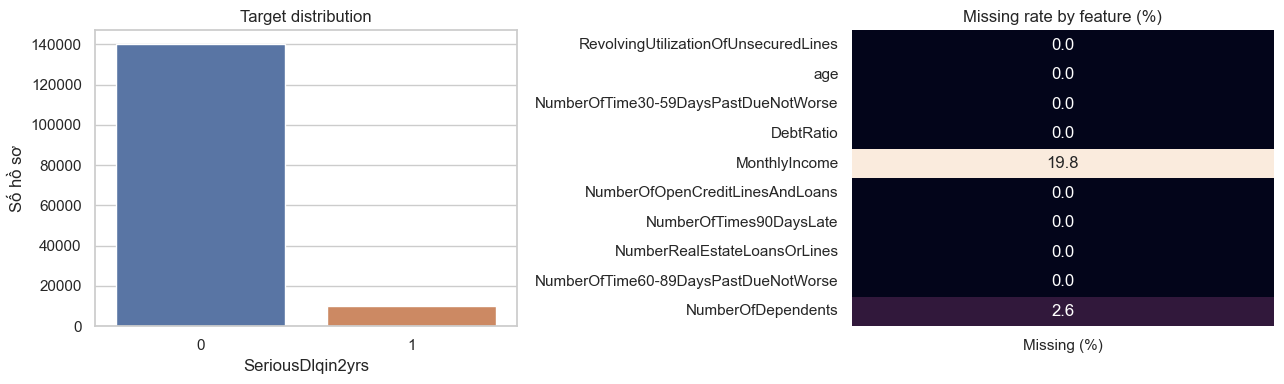

In [5]:
# Dấu hiệu bất thường: các giá trị này không nhất thiết phải xóa ngay; trước hết ghi nhận và xử lý nhất quán.
quality_checks = pd.DataFrame(index=feature_cols)
quality_checks['Số giá trị âm'] = (train[feature_cols] < 0).sum()
quality_checks['Số giá trị bằng 0'] = (train[feature_cols] == 0).sum()
quality_checks['Số giá trị vô hạn'] = np.isinf(train[feature_cols]).sum()
quality_checks['p99'] = train[feature_cols].quantile(.99)
quality_checks['p999'] = train[feature_cols].quantile(.999)
display(quality_checks)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train, x=TARGET, ax=axes[0], palette='deep')
axes[0].set_title('Target distribution')
axes[0].set_ylabel('Số hồ sơ')
sns.heatmap(train[feature_cols].isna().mean().mul(100).rename('Missing (%)').to_frame(), annot=True, fmt='.1f', cbar=False, yticklabels=True, ax=axes[1])
axes[1].set_title('Missing rate by feature (%)')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

## 3. Train/validation split và các metric đánh giá

Giữ riêng 25% số hồ sơ để kiểm định, duy trì tỷ lệ quá hạn khi chia mẫu. Các ngưỡng chia khoảng, trung vị và WOE được ước lượng trên tập train để tránh data leakage. AUC đo khả năng xếp hạng rủi ro. KS đo mức phân tách lớn nhất giữa hai nhóm khách hàng theo điểm dự báo. Hệ số Gini bằng `2 × AUC − 1`.

In [6]:
X = train[feature_cols].copy().replace([np.inf, -np.inf], np.nan)
y = train[TARGET].astype(int).copy()
X_test = test[feature_cols].copy().replace([np.inf, -np.inf], np.nan)

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_valid.shape, X_test.shape)

def ks_statistic(y_true, probability):
    fpr, tpr, _ = roc_curve(y_true, probability)
    return float(np.max(tpr - fpr))

def validation_metrics(y_true, probability, threshold=0.5):
    pred = (probability >= threshold).astype(int)
    auc = roc_auc_score(y_true, probability)
    return pd.Series({
        'AUC': auc,
        'Gini': 2 * auc - 1,
        'KS': ks_statistic(y_true, probability),
        'Brier': brier_score_loss(y_true, probability),
        'Log loss': log_loss(y_true, probability),
        f'Accuracy @ {threshold:.4g}': accuracy_score(y_true, pred),
        f'Precision @ {threshold:.4g}': precision_score(y_true, pred, zero_division=0),
        f'Recall @ {threshold:.4g}': recall_score(y_true, pred, zero_division=0),
        f'F1 @ {threshold:.4g}': f1_score(y_true, pred, zero_division=0),
    })

def plot_roc(y_true, probability, label):
    fpr, tpr, _ = roc_curve(y_true, probability)
    plt.plot(fpr, tpr, label=f'{label} (AUC={roc_auc_score(y_true, probability):.4f})')

def plot_calibration(y_true, probability, label, n_bins=10):
    observed, predicted = calibration_curve(y_true, probability, n_bins=n_bins, strategy='quantile')
    plt.plot(predicted, observed, marker='o', label=label)

(112500, 10) (37500, 10) (101503, 10)


## 4. Binning, Weight of Evidence (WOE) và Information Value (IV)

Trong mỗi khoảng, WOE là logarit của tỷ số giữa hai tỷ trọng: phần khách hàng không quá hạn thuộc khoảng đó và phần khách hàng quá hạn thuộc khoảng đó. IV tổng hợp mức phân tách của các khoảng để hỗ trợ sàng lọc biến. Khi chọn biến, cần xét cả ý nghĩa tín dụng và độ ổn định.

In [7]:
def fit_woe(X_fit, y_fit, max_bins=10, smoothing=0.5):
    edges_by_feature, woe_by_feature, iv_rows = {}, {}, []
    y_fit = pd.Series(y_fit, index=X_fit.index).astype(int)
    for col in X_fit.columns:
        x = pd.to_numeric(X_fit[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
        non_missing = x.dropna()
        if non_missing.nunique() <= 1:
            edges = np.array([-np.inf, np.inf])
        else:
            quantiles = np.linspace(0, 1, max_bins + 1)[1:-1]
            cuts = np.unique(non_missing.quantile(quantiles).to_numpy())
            edges = np.r_[-np.inf, cuts, np.inf]
        bins = pd.cut(x, bins=edges, labels=False, include_lowest=True).astype('float')
        bins = bins.fillna(-1).astype(int)
        bin_values = sorted(bins.unique())
        total_bad = max((y_fit == 1).sum(), 1)
        total_good = max((y_fit == 0).sum(), 1)
        table = pd.DataFrame({'bin': bins, 'target': y_fit}).groupby('bin')['target'].agg(['sum', 'count'])
        table['bad_n'] = table['sum']
        table['good_n'] = table['count'] - table['sum']
        table['dist_bad'] = (table['bad_n'] + smoothing) / (total_bad + smoothing * len(table))
        table['dist_good'] = (table['good_n'] + smoothing) / (total_good + smoothing * len(table))
        table['woe'] = np.log(table['dist_good'] / table['dist_bad'])
        table['iv_component'] = (table['dist_good'] - table['dist_bad']) * table['woe']
        edges_by_feature[col] = edges
        woe_by_feature[col] = table['woe'].to_dict()
        iv_rows.append({'Feature': col, 'IV': table['iv_component'].sum(), 'Number of bins': len(table)})
    return edges_by_feature, woe_by_feature, pd.DataFrame(iv_rows).sort_values('IV', ascending=False)

def transform_woe(X_new, edges_by_feature, woe_by_feature):
    output = pd.DataFrame(index=X_new.index)
    for col, edges in edges_by_feature.items():
        x = pd.to_numeric(X_new[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
        bins = pd.cut(x, bins=edges, labels=False, include_lowest=True).astype('float')
        bins = bins.fillna(-1).astype(int)
        mapping = woe_by_feature[col]
        output[col] = bins.map(mapping).fillna(0.0).astype(float)
    return output

edges, woe_maps, iv_table = fit_woe(X_train, y_train, max_bins=10)
X_train_woe = transform_woe(X_train, edges, woe_maps)
X_valid_woe = transform_woe(X_valid, edges, woe_maps)
X_test_woe = transform_woe(X_test, edges, woe_maps)
display(iv_table)

,Feature,IV,Number of bins
0,RevolvingUtilizationOfUnsecuredLines,1.107791,10
6,NumberOfTimes90DaysLate,0.843773,2
2,NumberOfTime30-59DaysPastDueNotWorse,0.725336,3
8,NumberOfTime60-89DaysPastDueNotWorse,0.574609,2
1,age,0.241668,10
3,DebtRatio,0.074544,10
4,MonthlyIncome,0.072272,11
5,NumberOfOpenCreditLinesAndLoans,0.066984,10
7,NumberRealEstateLoansOrLines,0.056131,4
9,NumberOfDependents,0.034500,5


In [8]:
# Tái lập kết quả gốc: cùng split, WOE, scaler và regularization như v1.
def new_logit():
    return Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(
        C=0.5, max_iter=1000, random_state=RANDOM_STATE))])

def metrics3(y, p):
    a = roc_auc_score(y, p)
    return pd.Series({'AUC': a, 'Gini': 2*a-1, 'KS': ks_statistic(y, p)})

baseline = new_logit().fit(X_train_woe, y_train)
before = metrics3(y_valid, baseline.predict_proba(X_valid_woe)[:, 1])
coef_before = pd.Series(baseline['model'].coef_[0], index=feature_cols)
display(before, coef_before)


AUC     0.858692
Gini    0.717383
KS      0.560965
dtype: float64

RevolvingUtilizationOfUnsecuredLines   -0.638828
age                                    -0.207745
NumberOfTime30-59DaysPastDueNotWorse   -0.343965
DebtRatio                              -0.208357
MonthlyIncome                          -0.021671
NumberOfOpenCreditLinesAndLoans         0.011695
NumberOfTimes90DaysLate                -0.329266
NumberRealEstateLoansOrLines           -0.140826
NumberOfTime60-89DaysPastDueNotWorse   -0.214576
NumberOfDependents                     -0.043362
dtype: float64

In [9]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from scipy.stats import binomtest
import statsmodels.api as sm


late = [c for c in feature_cols if 'DaysPastDue' in c or 'DaysLate' in c]
util = 'RevolvingUtilizationOfUnsecuredLines'
open_lines = 'NumberOfOpenCreditLinesAndLoans'
caps_cols = [util, 'DebtRatio']

def clean_feature(x, cap):
    x = x.copy()
    special = pd.Series('', index=x.index)
    special.loc[x.isna()] = 'Missing'
    if x.name in late:
        special.loc[x.isin([96, 98])] = 'Special 96/98'
    if x.name == 'age':
        special.loc[x.notna() & ~x.between(18, 100)] = 'Age ngoài phạm vi'
    if x.name == util:
        special.loc[x.eq(0)] = 'Utilization = 0'
    if cap is not None:
        x = x.clip(upper=cap)
    return x, special

def group_ids(x, rule):
    cap, cuts = rule
    values, special = clean_feature(x, cap)
    groups = pd.cut(values, [-np.inf, *cuts, np.inf], labels=False).fillna(0).astype(int)
    return groups.astype(str).where(special.eq(''), special)

def fit_bins(frame, target):
    rules, maps, tables = {}, {}, []
    for col in frame:
        x = frame[col]
        cap = x.quantile(.995) if col in caps_cols else None
        values, special = clean_feature(x, cap)
        v = values[special.eq('')]
        if col in late or col in ['NumberOfDependents', 'NumberRealEstateLoansOrLines', open_lines]:
            cuts = np.unique(v.clip(upper=15))[:-1].tolist()
        else:
            cuts = np.unique(v.quantile(np.arange(.1,1,.1))).tolist()
        # Gộp bin thường theo quy mô và số bad, sau đó theo chiều rủi ro tăng.
        raw = np.searchsorted(cuts, v, side='left')
        counts = np.bincount(raw, minlength=len(cuts)+1)
        bads = np.bincount(raw, weights=target.loc[v.index], minlength=len(cuts)+1)
        blocks = [[n,b] for n,b in zip(counts,bads)]
        while len(blocks)>1:
            rates = [(b+.5)/(n+1) for n,b in blocks]
            thin = next((i for i,(n,b) in enumerate(blocks) if n < .005*len(frame) or b < 20), None)
            if thin is not None:
                adj = [j for j in [thin-1,thin+1] if 0<=j<len(blocks)]
                i = min(thin,min(adj,key=lambda j:abs(rates[j]-rates[thin])))
            elif col in late+[util] and any(np.diff(rates)<0):
                i = np.flatnonzero(np.diff(rates)<0)[0]
            else:
                break
            blocks[i] = [a+b for a,b in zip(blocks[i],blocks.pop(i+1))]
            cuts.pop(i)
        rules[col] = cap,cuts
        ids = group_ids(x,rules[col])
        t = target.groupby(ids).agg(n='size',bad='sum')
        t['bad_rate'] = t.bad/t.n
        g = (t.n-t.bad+.5)/((t.n-t.bad).sum()+.5*len(t))
        b = (t.bad+.5)/(t.bad.sum()+.5*len(t))
        t['WOE'] = np.log(g/b)
        t['IV_part'] = (g-b)*t.WOE
        maps[col] = t.WOE.to_dict()
        bounds = [-np.inf,*cuts,np.inf]
        t['Khoảng'] = [f'({bounds[int(k)]:.5g}, {bounds[int(k)+1]:.5g}]' if k.isdigit() else k for k in t.index]
        order = sorted(t.index,key=lambda k:(not k.isdigit(), int(k) if k.isdigit() else k))
        tables.append(t.loc[order].rename_axis('Bin').reset_index().assign(Feature=col))
    return rules,maps,pd.concat(tables,ignore_index=True)

def encode(frame,rules,maps):
    return pd.DataFrame({c:group_ids(frame[c],rules[c]).map(maps[c]).fillna(0.)
                         for c in rules},index=frame.index)

rules,maps,details = fit_bins(X_train,y_train)
Z = encode(X_train,rules,maps)
Zv = encode(X_valid,rules,maps)
Zt = encode(X_test,rules,maps)
audit_rows = []
for c in late:
    for code in [96,98]:
        mask = X_train[c].eq(code)
        audit_rows.append((c,str(code),'Bin special chung; ý nghĩa mã cần xác minh',mask.sum(),y_train[mask].mean()))
def audit_rule(c,mask,problem,action):
    audit_rows.append((c,problem,action,mask.sum(),y_train[mask].mean()))
audit_rule('age',~X_train.age.between(18,100) & X_train.age.notna(),'Ngoài [18,100] (giả định)','Bin special',)
for c in caps_cols:
    cap = rules[c][0]
    audit_rule(c,X_train[c]>cap,'Đuôi phải',f'Cap tại P99.5 train = {cap:.5g}')
audit_rule(util,X_train[util].eq(0),'Không sử dụng hạn mức','Tách bin để so với mức sử dụng thấp')
display(pd.DataFrame(audit_rows,columns=['Biến','Vấn đề','Quy tắc','Số hồ sơ train','Bad rate']))
with pd.option_context('display.max_rows',None):
    display(details)
def monotone(group):
    w = group.loc[group.Bin.str.isdigit(),'WOE']
    return w.is_monotonic_increasing or w.is_monotonic_decreasing
iv_table = details.groupby('Feature').IV_part.sum().rename('IV').sort_values(ascending=False).reset_index()
iv_table['IV > 0.5: cần rà soát'] = iv_table.IV.gt(.5)
iv_table['WOE đơn điệu (bin thường)'] = iv_table.Feature.map({c:monotone(g) for c,g in details.groupby('Feature')})
display(iv_table)
u = details[details.Feature.eq(util)].set_index('Bin')
print(f"Bad rate khi utilization = 0: {u.loc['Utilization = 0','bad_rate']:.2%}; bin dương thấp nhất: {u.loc['0','bad_rate']:.2%}. Giữ riêng trạng thái không sử dụng hạn mức.")


,Biến,Vấn đề,Quy tắc,Số hồ sơ train,Bad rate
0,NumberOfTime30-59DaysPastDueNotWorse,96,Bin special chung; ý nghĩa mã cần xác minh,1,1.000000
1,NumberOfTime30-59DaysPastDueNotWorse,98,Bin special chung; ý nghĩa mã cần xác minh,201,0.532338
2,NumberOfTimes90DaysLate,96,Bin special chung; ý nghĩa mã cần xác minh,1,1.000000
3,NumberOfTimes90DaysLate,98,Bin special chung; ý nghĩa mã cần xác minh,201,0.532338
4,NumberOfTime60-89DaysPastDueNotWorse,96,Bin special chung; ý nghĩa mã cần xác minh,1,1.000000
5,NumberOfTime60-89DaysPastDueNotWorse,98,Bin special chung; ý nghĩa mã cần xác minh,201,0.532338
6,age,"Ngoài [18,100] (giả định)",Bin special,6,0.166667
7,RevolvingUtilizationOfUnsecuredLines,Đuôi phải,Cap tại P99.5 train = 1.3836,563,0.303730
8,DebtRatio,Đuôi phải,Cap tại P99.5 train = 6237.5,563,0.074600
9,RevolvingUtilizationOfUnsecuredLines,Không sử dụng hạn mức,Tách bin để so với mức sử dụng thấp,8250,0.028485


,Bin,n,bad,bad_rate,WOE,IV_part,Khoảng,Feature
0,0,10425,144,0.013813,1.629297,1.282765e-01,"(-inf, 0.012777]",RevolvingUtilizationOfUnsecuredLines
1,1,10425,154,0.014772,1.561409,1.207081e-01,"(0.012777, 0.031767]",RevolvingUtilizationOfUnsecuredLines
2,2,10425,162,0.015540,1.510146,1.150246e-01,"(0.031767, 0.060801]",RevolvingUtilizationOfUnsecuredLines
3,3,10425,233,0.022350,1.140700,7.535124e-02,"(0.060801, 0.10854]",RevolvingUtilizationOfUnsecuredLines
4,4,10426,273,0.026185,0.978747,5.908721e-02,"(0.10854, 0.19048]",RevolvingUtilizationOfUnsecuredLines
5,5,10424,405,0.038853,0.571643,2.375377e-02,"(0.19048, 0.31614]",RevolvingUtilizationOfUnsecuredLines
6,6,10425,599,0.057458,0.161217,2.246748e-03,"(0.31614, 0.49335]",RevolvingUtilizationOfUnsecuredLines
7,7,10425,1058,0.101487,-0.455132,2.340673e-02,"(0.49335, 0.74091]",RevolvingUtilizationOfUnsecuredLines
8,8,10425,1843,0.176787,-1.097466,1.791259e-01,"(0.74091, 0.99641]",RevolvingUtilizationOfUnsecuredLines
9,9,10425,2414,0.231559,-1.436139,3.511819e-01,"(0.99641, inf]",RevolvingUtilizationOfUnsecuredLines


,Feature,IV,IV > 0.5: cần rà soát,WOE đơn điệu (bin thường)
0,RevolvingUtilizationOfUnsecuredLines,1.118347,True,True
1,NumberOfTimes90DaysLate,0.877735,True,True
2,NumberOfTime30-59DaysPastDueNotWorse,0.744151,True,True
3,NumberOfTime60-89DaysPastDueNotWorse,0.599770,True,True
4,age,0.242247,False,True
5,NumberOfOpenCreditLinesAndLoans,0.112829,False,False
6,DebtRatio,0.074544,False,False
7,MonthlyIncome,0.072272,False,False
8,NumberRealEstateLoansOrLines,0.064625,False,False
9,NumberOfDependents,0.034887,False,True


Bad rate khi utilization = 0: 2.85%; bin dương thấp nhất: 1.38%. Giữ riêng trạng thái không sử dụng hạn mức.


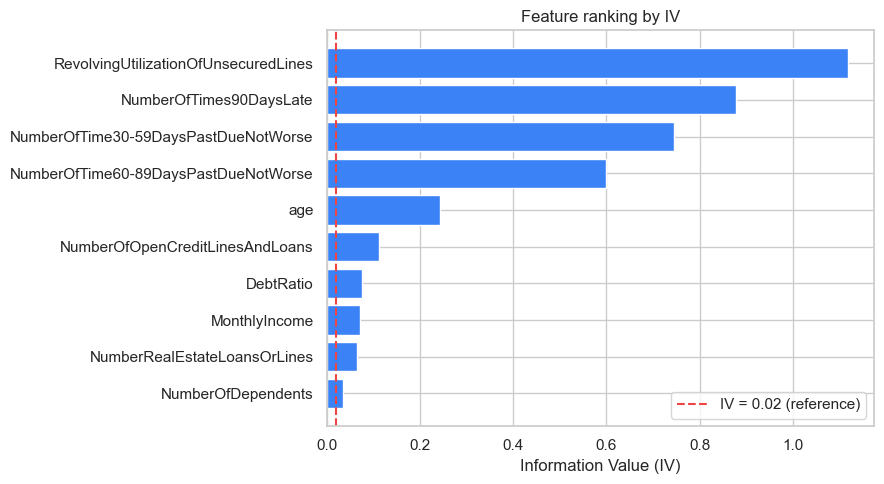

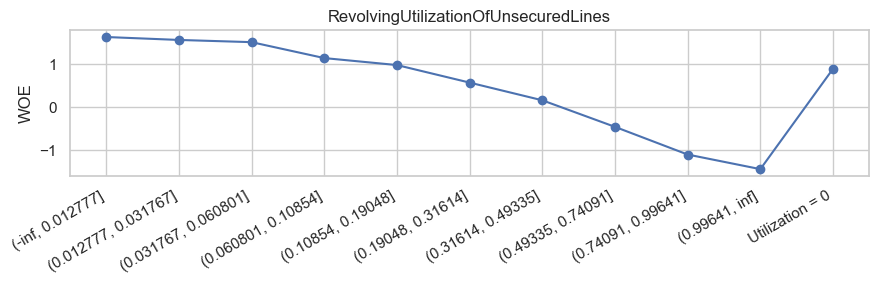

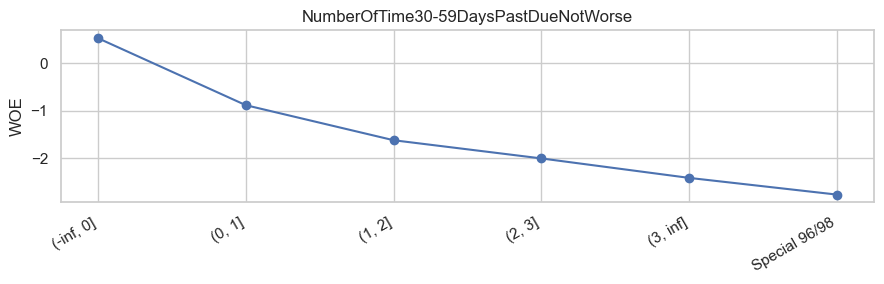

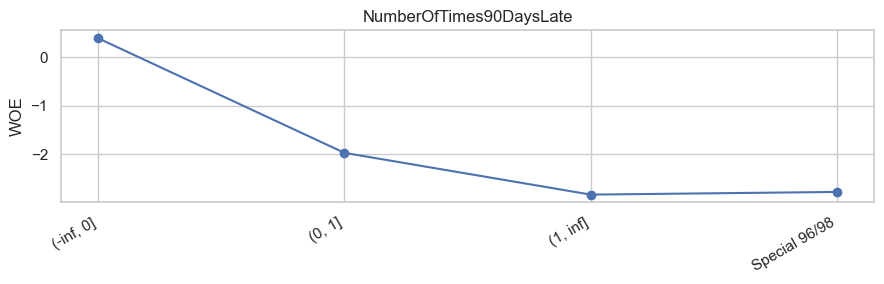

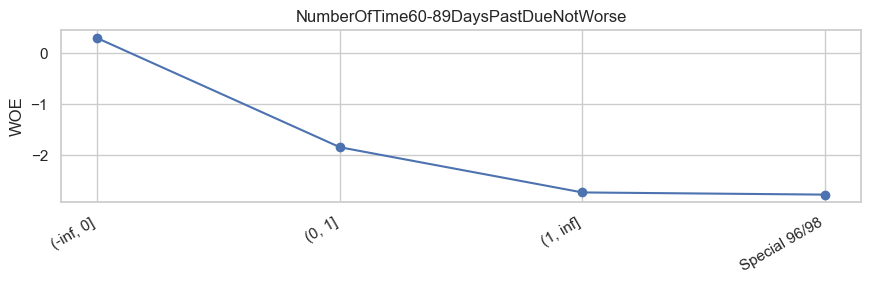

In [10]:
plt.figure(figsize=(9, 5))
top_iv = iv_table.head(15).sort_values('IV')
plt.barh(top_iv['Feature'], top_iv['IV'], color='#3b82f6')
plt.axvline(0.02, color='#ef4444', linestyle='--', label='IV = 0.02 (reference)')
plt.title('Feature ranking by IV')
plt.xlabel('Information Value (IV)')
plt.legend()
plt.tight_layout()
plt.show()

for c in [util,*late]:
    d = details[details.Feature.eq(c)]
    plt.figure(figsize=(9,3)); plt.plot(d['Khoảng'],d.WOE,marker='o'); plt.xticks(rotation=30,ha='right'); plt.title(c); plt.ylabel('WOE'); plt.tight_layout(); plt.show()

## 5. So sánh scorecard với benchmark

Scorecard dùng Logistic Regression trên các biến đã mã hóa WOE. Mô hình benchmark dùng HistGradientBoosting sau khi điền giá trị thiếu. So sánh trên cùng tập validation giúp đánh giá mức cải thiện về khả năng phân biệt khi dùng mô hình phi tuyến.

In [11]:
def inference(z,y):
    standardized = (z-z.mean())/z.std(ddof=0)
    fit = sm.Logit(y, sm.add_constant(standardized)).fit(disp=False)
    return pd.concat([fit.params.rename('Beta'),fit.pvalues.rename('p'),fit.conf_int().set_axis(['CI low','CI high'],axis=1)],axis=1).drop('const')
def select(z,y):
    cols = list(z)
    while True:
        info = inference(z[cols],y)
        wrong = info[info.Beta>=0]
        if len(wrong):
            cols.remove(wrong.Beta.idxmax())
        elif info.p.max()>.05:
            cols.remove(info.p.idxmax())
        else:
            return cols
corr = Z.corr()
display(corr.round(2))
info = inference(Z,y_train)
info['VIF'] = np.diag(np.linalg.inv(corr))
info['Beta v1 (chuẩn hóa)'] = coef_before
display(info)
display(pd.concat([inference(X_train_woe[[open_lines]],y_train).loc[open_lines],
                   inference(X_train_woe,y_train).loc[open_lines]],axis=1,keys=['Đơn biến v1','Đa biến v1']))
print('Nếu beta đơn biến âm nhưng beta đa biến dương, quan hệ biên đã đảo dấu sau khi kiểm soát các WOE khác. VIF và tương quan là chỉ báo, chưa chứng minh nguyên nhân nhân quả.')
print('Tương quan WOE lớn nhất với số khoản vay mở (v1):')
display(X_train_woe.corr()[open_lines].drop(open_lines).abs().nlargest(3))
keep = select(Z,y_train)
print('Quy tắc train: loại lần lượt beta không âm rồi p > 0.05; giữ:',keep)
print('Dấu đơn biến và đa biến có thể khác khi điều chỉnh các biến tương quan. CI/p-value mô tả có điều kiện theo bin đã fit; không hiệu chỉnh cho quá trình chọn biến.')
X_train_woe, X_valid_woe, X_test_woe = Z[keep], Zv[keep], Zt[keep]

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
RevolvingUtilizationOfUnsecuredLines,1.00,0.28,0.26,0.14,0.12,0.27,0.28,0.09,0.22,0.10
age,0.28,1.00,0.10,0.08,0.08,0.07,0.10,0.00,0.09,0.28
NumberOfTime30-59DaysPastDueNotWorse,0.26,0.10,1.00,0.08,0.03,0.02,0.29,0.01,0.33,0.07
DebtRatio,0.14,0.08,0.08,1.00,0.25,-0.10,0.01,-0.08,0.03,0.11
MonthlyIncome,0.12,0.08,0.03,0.25,1.00,0.09,0.08,0.13,0.05,-0.06
NumberOfOpenCreditLinesAndLoans,0.27,0.07,0.02,-0.10,0.09,1.00,0.20,0.27,0.08,-0.10
NumberOfTimes90DaysLate,0.28,0.10,0.29,0.01,0.08,0.20,1.00,0.08,0.34,0.03
NumberRealEstateLoansOrLines,0.09,0.00,0.01,-0.08,0.13,0.27,0.08,1.00,0.04,-0.12
NumberOfTime60-89DaysPastDueNotWorse,0.22,0.09,0.33,0.03,0.05,0.08,0.34,0.04,1.00,0.04
NumberOfDependents,0.10,0.28,0.07,0.11,-0.06,-0.10,0.03,-0.12,0.04,1.00


,Beta,p,CI low,CI high,VIF,Beta v1 (chuẩn hóa)
RevolvingUtilizationOfUnsecuredLines,-0.643962,0.000000e+00,-0.673826,-0.614097,1.325205,-0.638828
age,-0.204549,2.445194e-32,-0.238412,-0.170687,1.175014,-0.207745
NumberOfTime30-59DaysPastDueNotWorse,-0.336469,1.892779e-237,-0.356510,-0.316427,1.215040,-0.343965
DebtRatio,-0.208742,2.203414e-58,-0.234139,-0.183345,1.132314,-0.208357
MonthlyIncome,-0.024863,7.793695e-02,-0.052507,0.002781,1.119122,-0.021671
NumberOfOpenCreditLinesAndLoans,0.012361,2.773232e-01,-0.009941,0.034663,1.213199,0.011695
NumberOfTimes90DaysLate,-0.327120,0.000000e+00,-0.343328,-0.310911,1.256136,-0.329266
NumberRealEstateLoansOrLines,-0.160450,1.512061e-31,-0.187362,-0.133538,1.107121,-0.140826
NumberOfTime60-89DaysPastDueNotWorse,-0.200497,5.110133e-122,-0.217226,-0.183768,1.224236,-0.214576
NumberOfDependents,-0.049992,2.582641e-04,-0.076808,-0.023177,1.132880,-0.043362


,Đơn biến v1,Đa biến v1
Beta,-2.406349e-01,0.010328
p,6.864527e-118,0.442937
CI low,-2.610670e-01,-0.016055
CI high,-2.202027e-01,0.036710


Nếu beta đơn biến âm nhưng beta đa biến dương, quan hệ biên đã đảo dấu sau khi kiểm soát các WOE khác. VIF và tương quan là chỉ báo, chưa chứng minh nguyên nhân nhân quả.
Tương quan WOE lớn nhất với số khoản vay mở (v1):


NumberRealEstateLoansOrLines            0.281255
RevolvingUtilizationOfUnsecuredLines    0.207856
NumberOfTimes90DaysLate                 0.136915
Name: NumberOfOpenCreditLinesAndLoans, dtype: float64

Quy tắc train: loại lần lượt beta không âm rồi p > 0.05; giữ: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
Dấu đơn biến và đa biến có thể khác khi điều chỉnh các biến tương quan. CI/p-value mô tả có điều kiện theo bin đã fit; không hiệu chỉnh cho quá trình chọn biến.


,WOE Logistic Scorecard,HistGradientBoosting
AUC,0.85970,0.86814
Gini,0.71940,0.73628
KS,0.56120,0.57986
Brier,0.04996,0.04871
Log loss,0.18195,0.17639
Accuracy @ 0.5,0.93717,0.93792
Precision @ 0.5,0.59518,0.61294
Recall @ 0.5,0.18715,0.19274
F1 @ 0.5,0.28476,0.29326


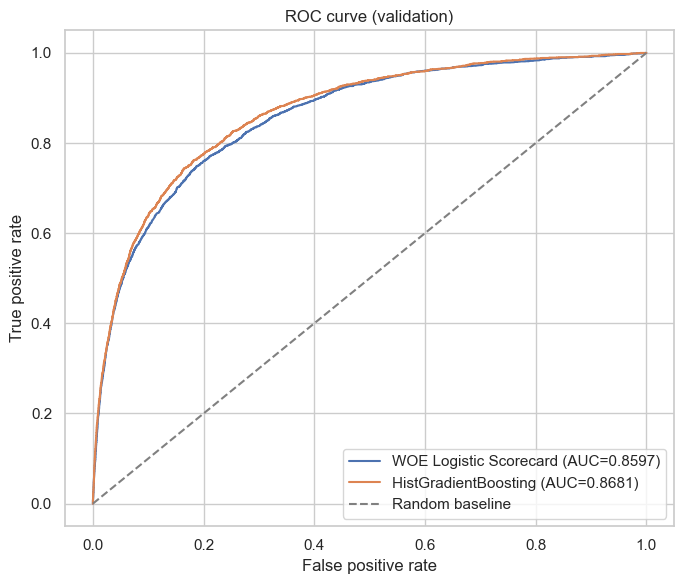

In [12]:
scorecard = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=0.5, max_iter=1000, class_weight=None, random_state=RANDOM_STATE))
])
scorecard.fit(X_train_woe, y_train)
p_scorecard = scorecard.predict_proba(X_valid_woe)[:, 1]

benchmark = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('model', HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.06, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=RANDOM_STATE
    ))
])
benchmark.fit(X_train, y_train)
p_benchmark = benchmark.predict_proba(X_valid)[:, 1]

comparison = pd.concat([
    validation_metrics(y_valid, p_scorecard).rename('WOE Logistic Scorecard'),
    validation_metrics(y_valid, p_benchmark).rename('HistGradientBoosting')
], axis=1)
display(comparison.round(5))

plt.figure(figsize=(7, 6))
plot_roc(y_valid, p_scorecard, 'WOE Logistic Scorecard')
plot_roc(y_valid, p_benchmark, 'HistGradientBoosting')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Random baseline')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curve (validation)'); plt.legend(); plt.tight_layout(); plt.show()

In [13]:
after = metrics3(y_valid,p_scorecard)
delta = pd.concat([before,after,after-before],axis=1,keys=['Trước','Sau','Chênh lệch'])
display(delta)
coef_after = pd.Series(scorecard['model'].coef_[0],index=keep)
display(pd.concat([coef_before,coef_after],axis=1,keys=['Beta trước','Beta sau']))
print('Hệ số tính trên WOE chuẩn hóa; bin thay đổi giữa hai phiên bản.')
raw_full = new_logit().fit(Z,y_train)
display(pd.concat([metrics3(y_valid,raw_full.predict_proba(Zv)[:,1]),after],axis=1,keys=['Bin mới, đủ biến','Sau chọn biến']))
# Bootstrap phân tầng có cặp: cùng trọng số hồ sơ cho cả hai mô hình.
def bootstrap(y,probs,B=1000):
    labels = np.asarray(y)
    rng = np.random.default_rng(RANDOM_STATE)
    configs = []
    for p in probs:
        ix = np.argsort(-p,kind='stable')
        ends = np.r_[np.flatnonzero(np.diff(p[ix])!=0),len(p)-1]
        configs.append((ix,ends))
    ids = [np.flatnonzero(labels==v) for v in (0,1)]
    stats = np.empty((B,len(probs),3))
    for i in range(B):
        w = np.bincount(np.concatenate([rng.choice(a,len(a)) for a in ids]),minlength=len(y))
        for j,(ix,ends) in enumerate(configs):
            t = np.r_[0,np.cumsum((w*labels)[ix])[ends]/len(ids[1])]
            f = np.r_[0,np.cumsum((w*(1-labels))[ix])[ends]/len(ids[0])]
            a = ((t[1:]+t[:-1])*np.diff(f)).sum()/2
            stats[i,j] = a,2*a-1,max(t-f)
    return stats
bs = bootstrap(y_valid,[p_scorecard,p_benchmark])
for j,name in enumerate(['Scorecard','Benchmark']):
    display(pd.DataFrame(np.quantile(bs[:,j,:],[.025,.975],axis=0),index=['CI low','CI high'],columns=after.index).assign(Model=name))
gap_ci = np.quantile(bs[:,1,0]-bs[:,0,0],[.025,.975])
print('AUC benchmark − scorecard, paired CI:',gap_ci)

,Trước,Sau,Chênh lệch
AUC,0.858692,0.859699,0.001007
Gini,0.717383,0.719397,0.002014
KS,0.560965,0.561199,0.000234


,Beta trước,Beta sau
RevolvingUtilizationOfUnsecuredLines,-0.638828,-0.642106
age,-0.207745,-0.207099
NumberOfTime30-59DaysPastDueNotWorse,-0.343965,-0.337254
DebtRatio,-0.208357,-0.215644
MonthlyIncome,-0.021671,NaN
NumberOfOpenCreditLinesAndLoans,0.011695,NaN
NumberOfTimes90DaysLate,-0.329266,-0.326563
NumberRealEstateLoansOrLines,-0.140826,-0.158938
NumberOfTime60-89DaysPastDueNotWorse,-0.214576,-0.201112
NumberOfDependents,-0.043362,-0.049343


Hệ số tính trên WOE chuẩn hóa; bin thay đổi giữa hai phiên bản.


,"Bin mới, đủ biến",Sau chọn biến
AUC,0.859762,0.859699
Gini,0.719525,0.719397
KS,0.561263,0.561199


,AUC,Gini,KS,Model
CI low,0.851713,0.703425,0.54521,Scorecard
CI high,0.866973,0.733946,0.57928,Scorecard


,AUC,Gini,KS,Model
CI low,0.860182,0.720365,0.563930,Benchmark
CI high,0.875374,0.750747,0.598482,Benchmark


AUC benchmark − scorecard, paired CI: [0.00604417 0.01080356]


### Chọn decision threshold theo mục tiêu kinh doanh

Ngưỡng minh họa tối đa hóa chỉ số J của Youden, bằng độ nhạy cộng độ đặc hiệu trừ một. Khi phê duyệt tín dụng, cần cân nhắc tổn thất do bỏ sót khách hàng rủi ro, chi phí từ chối nhầm và khẩu vị rủi ro.

,Fold,Model,AUC,Gini,KS
0,1,Scorecard,0.860850,0.721700,0.567876
1,1,Benchmark,0.868792,0.737585,0.579198
2,2,Scorecard,0.860064,0.720127,0.562298
3,2,Benchmark,0.868400,0.736800,0.591906
4,3,Scorecard,0.851878,0.703756,0.550511
5,3,Benchmark,0.859903,0.719805,0.577137
6,4,Scorecard,0.855316,0.710632,0.550619
7,4,Benchmark,0.863401,0.726802,0.576556
8,5,Scorecard,0.853039,0.706077,0.543170
9,5,Benchmark,0.862281,0.724562,0.570825


AUC                  KS          
               mean       std      mean       std
Model                                            
Benchmark  0.864555  0.003901  0.579124  0.007791
Scorecard  0.856229  0.004062  0.554895  0.009978

,Quy tắc OOF,Threshold,Flag rate,Recall,Precision,FN,FP
0,Youden,0.065423,0.245440,0.766560,0.208714,585,7283
1,FN:FP = 3:1,0.207095,0.067493,0.440144,0.435796,1403,1428
2,FN:FP = 5:1,0.143447,0.096880,0.537111,0.370493,1160,2287
3,FN:FP = 10:1,0.084553,0.189067,0.701117,0.247814,749,5333


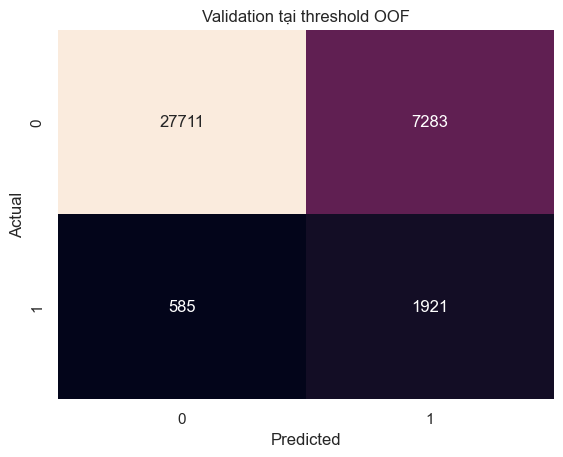

In [14]:
oof = pd.Series(index=y_train.index,dtype=float)
fold_rows = []
for fold,(dev,hold) in enumerate(StratifiedKFold(5,shuffle=True,random_state=RANDOM_STATE).split(X_train,y_train),1):
    a,b = X_train.iloc[dev],X_train.iloc[hold]
    ya,yb = y_train.iloc[dev],y_train.iloc[hold]
    r,m,_ = fit_bins(a,ya)
    za,zb = encode(a,r,m),encode(b,r,m)
    cols = select(za,ya)
    s = new_logit().fit(za[cols],ya).predict_proba(zb[cols])[:,1]
    h = clone(benchmark).fit(a,ya).predict_proba(b)[:,1]
    oof.loc[b.index] = s
    for name,p in [('Scorecard',s),('Benchmark',h)]:
        fold_rows.append(dict(Fold=fold,Model=name,**metrics3(yb,p)))
folds = pd.DataFrame(fold_rows)
display(folds,folds.groupby('Model')[['AUC','KS']].agg(['mean','std']))
f,t,thresholds = roc_curve(y_train,oof,drop_intermediate=False)
rate = y_train.mean()
choices = {'Youden':thresholds[np.argmax(t-f)]}
for cost in [3,5,10]:
    choices[f'FN:FP = {cost}:1'] = thresholds[np.argmin(cost*rate*(1-t)+(1-rate)*f)]
rows = []
for name,cut in choices.items():
    pred = p_scorecard>=cut
    tn,fp,fn,tp = confusion_matrix(y_valid,pred).ravel()
    rows.append([name,cut,pred.mean(),tp/(tp+fn),tp/max(tp+fp,1),fn,fp])
display(pd.DataFrame(rows,columns=['Quy tắc OOF','Threshold','Flag rate','Recall','Precision','FN','FP']))
best_threshold = choices['Youden']
cm = confusion_matrix(y_valid,p_scorecard>=best_threshold)
sns.heatmap(cm,annot=True,fmt='d',cbar=False)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Validation tại threshold OOF'); plt.show()

## 6. Calibration và hệ số của scorecard

Calibration curve so sánh xác suất dự báo trung bình với tỷ lệ quá hạn thực tế trong từng nhóm. Hai giá trị càng gần nhau, xác suất dự báo của nhóm càng sát thực tế. Khi đọc hệ số hồi quy, cần đối chiếu dấu của hệ số với quy ước tính WOE.

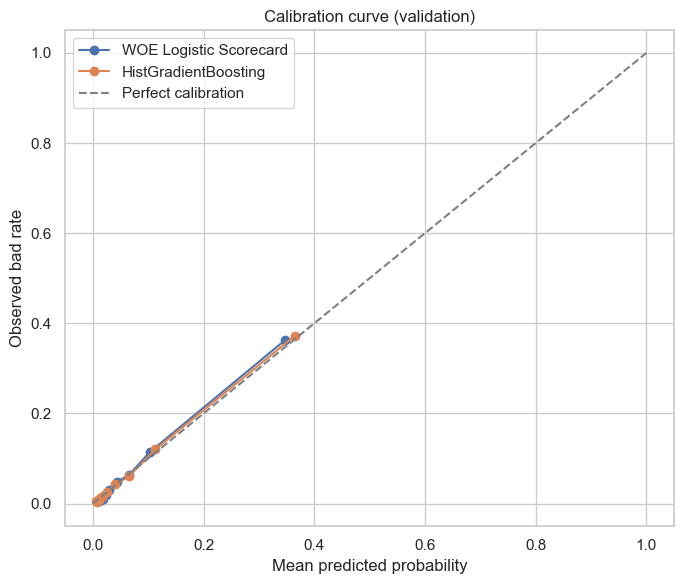

In [15]:
plt.figure(figsize=(7, 6))
plot_calibration(y_valid, p_scorecard, 'WOE Logistic Scorecard')
plot_calibration(y_valid, p_benchmark, 'HistGradientBoosting')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed bad rate')
plt.title('Calibration curve (validation)'); plt.legend(); plt.tight_layout(); plt.show()



In [16]:
def deciles(train_p,valid_p):
    edges = np.unique(np.quantile(train_p,np.arange(1,10)/10))
    g = pd.DataFrame({'p':valid_p,'bad':y_valid,'bin':np.digitize(valid_p,edges)})
    d = g.groupby('bin').agg(n=('p','size'),bad=('bad','sum'),expected=('p','mean')).sort_index(ascending=False)
    d['bad rate'] = d.bad/d.n
    d['cum bad'] = d.bad.cumsum()/d.bad.sum()
    d['cum good'] = (d.n-d.bad).cumsum()/(d.n-d.bad).sum()
    d['KS decile'] = d['cum bad']-d['cum good']
    d['p binomial (xấp xỉ)'] = [binomtest(int(b),int(n),p).pvalue for b,n,p in zip(d.bad,d.n,d.expected)]
    return d
train_p = scorecard.predict_proba(Z[keep])[:,1]
for name,ref,p in [('Scorecard',train_p,p_scorecard),('Benchmark',benchmark.predict_proba(X_train)[:,1],p_benchmark)]:
    print(f'{name}: mean PD {p.mean():.3%}, bad rate {y_valid.mean():.3%}, gap {p.mean()-y_valid.mean():+.3%}')
    display(deciles(ref,p))
print('Binomial test dùng xác suất trung bình của nhóm; p-value mang tính thăm dò do PD trong nhóm khác nhau và có nhiều phép thử.')

Scorecard: mean PD 6.652%, bad rate 6.683%, gap -0.031%


,n,bad,expected,bad rate,cum bad,cum good,KS decile,p binomial (xấp xỉ)
bin,,,,,,,,
9,3679,1348,0.351695,0.366404,0.537909,0.066611,0.471298,0.062263
8,3716,432,0.104083,0.116254,0.710295,0.160456,0.549839,0.016782
7,3883,249,0.065331,0.064126,0.809657,0.264302,0.545354,0.795017
6,3707,179,0.043023,0.048287,0.881085,0.365120,0.515966,0.114422
5,3806,116,0.030135,0.030478,0.927374,0.470566,0.456808,0.886859
4,3751,74,0.023033,0.019728,0.956903,0.575642,0.381262,0.191235
3,3747,35,0.018203,0.009341,0.970870,0.681717,0.289153,0.000013
2,3712,27,0.014658,0.007274,0.981644,0.787021,0.194623,0.000052
1,3722,24,0.011741,0.006448,0.991221,0.892696,0.098525,0.001722


Benchmark: mean PD 6.663%, bad rate 6.683%, gap -0.019%


,n,bad,expected,bad rate,cum bad,cum good,KS decile,p binomial (xấp xỉ)
bin,,,,,,,,
9,3714,1389,0.367040,0.373990,0.554270,0.066440,0.487830,0.385336
8,3701,448,0.114320,0.121048,0.733041,0.159399,0.573642,0.196569
7,3884,243,0.065952,0.062564,0.830008,0.263445,0.566563,0.418925
6,3761,158,0.040377,0.042010,0.893057,0.366406,0.526651,0.590332
5,3669,96,0.026108,0.026165,0.931365,0.468509,0.462856,0.958704
4,3803,63,0.017782,0.016566,0.956504,0.575384,0.381120,0.623421
3,3716,44,0.013331,0.011841,0.974062,0.680317,0.293746,0.474337
2,3715,32,0.010633,0.008614,0.986832,0.785563,0.201268,0.262135
1,3735,13,0.008303,0.003481,0.992019,0.891924,0.100095,0.000405


Binomial test dùng xác suất trung bình của nhóm; p-value mang tính thăm dò do PD trong nhóm khác nhau và có nhiều phép thử.


## 7. Đánh giá độ ổn định của dữ liệu đầu vào bằng PSI

Population Stability Index (PSI) so sánh phân phối từng biến giữa tập train và tập test. Các mốc 0,10 và 0,25 là ngưỡng tham khảo để xác định biến cần xem xét. Muốn kết luận mô hình dự báo kém đi, cần có kết quả trả nợ thực tế.

In [17]:
def drift(ref,cur):
    a,b = ref.value_counts(),cur.value_counts()
    idx = a.index.union(b.index)
    a,b = a.reindex(idx,fill_value=0),b.reindex(idx,fill_value=0)
    p,q = (a+.5)/(a.sum()+.5*len(idx)),(b+.5)/(b.sum()+.5*len(idx))
    return pd.DataFrame({'n train':a,'n test':b,'train share':p,'test share':q,'PSI part':(p-q)*np.log(p/q)})
def psi_numeric(ref,cur):
    cuts = np.unique(ref.dropna().quantile(np.arange(.1,1,.1)))
    def ids(x):
        return pd.cut(x,[-np.inf,*cuts,np.inf],labels=False).fillna(-1).astype(int)
    return drift(ids(ref),ids(cur))
csi = pd.concat({c:drift(group_ids(X_train[c],rules[c]),group_ids(X_test[c],rules[c])) for c in feature_cols},names=['Feature','Bin'])
psi_table = csi.groupby(level=0)['PSI part'].sum().rename('PSI (train vs. test)').reset_index()
psi_table['missing train'] = psi_table.Feature.map(X_train.isna().mean())
psi_table['missing test'] = psi_table.Feature.map(X_test.isna().mean())
display(psi_table)
with pd.option_context('display.max_rows',None):
    display(csi.loc[keep])
score_drift = psi_numeric(pd.Series(train_p),pd.Series(scorecard.predict_proba(Zt[keep])[:,1]))
score_psi = score_drift['PSI part'].sum()
display(score_drift)
print(f'Score PSI = {score_psi:.6f}. So sánh hai mẫu Kaggle cùng nguồn, giả định tách ngẫu nhiên; thiếu mốc thời gian để đánh giá ổn định qua kỳ.')

,Feature,PSI (train vs. test),missing train,missing test
0,DebtRatio,0.000087,0.000000,0.000000
1,MonthlyIncome,0.000346,0.197218,0.198053
2,NumberOfDependents,0.000168,0.026178,0.025871
3,NumberOfOpenCreditLinesAndLoans,0.000122,0.000000,0.000000
4,NumberOfTime30-59DaysPastDueNotWorse,0.000068,0.000000,0.000000
5,NumberOfTime60-89DaysPastDueNotWorse,0.000061,0.000000,0.000000
6,NumberOfTimes90DaysLate,0.000054,0.000000,0.000000
7,NumberRealEstateLoansOrLines,0.000188,0.000000,0.000000
8,RevolvingUtilizationOfUnsecuredLines,0.000239,0.000000,0.000000
9,age,0.000186,0.000000,0.000000


n train  n test  \
Feature                              Bin                                  
RevolvingUtilizationOfUnsecuredLines 0                    10425    9293   
                                     1                    10425    9483   
                                     2                    10425    9481   
                                     3                    10425    9478   
                                     4                    10426    9391   
                                     5                    10424    9474   
                                     6                    10425    9147   
                                     7                    10425    9303   
                                     8                    10425    9711   
                                     9                    10425    9431   
                                     Utilization = 0       8250    7311   
age                                  0                    12820   11291   
                                     1                    11205   10077   
                                     2                    11819   10729   
                                     3                    11111   10019   
                                     4                    11119   10036   
                                     5                    10693    9626   
                                     6                     9991    8948   
                                     7                    12423   11135   
                                     8                    10600    9833   
                                     9                    10713    9806   
                                     Age ngoài phạm vi        6       3   
NumberOfTime30-59DaysPastDueNotWorse 0                    94474   85190   
                                     1                    12077   10837   
                                     2                     3447    3168   
                                     3                     1330    1201   
                                     4                      970     893   
                                     Special 96/98          202     214   
DebtRatio                            0                    11250   10142   
                                     1                    11250   10300   
                                     2                    11250   10236   
                                     3                    11250   10086   
                                     4                    11250   10232   
                                     5                    11250   10047   
                                     6                    11250   10180   
                                     7                    11250    9991   
                                     8                    11250   10223   
                                     9                    11250   10066   
NumberOfTimes90DaysLate              0                   106204   95785   
                                     1                     3956    3594   
                                     2                     2138    1910   
                                     Special 96/98          202     214   
NumberRealEstateLoansOrLines         0                    42132   38066   
                                     1                    39255   35670   
                                     2                    23677   20955   
                                     3                     4709    4423   
                                     4                     1601    1414   
                                     5                     1126     975   
NumberOfTime60-89DaysPastDueNotWorse 0                   106775   96375   
                                     1                     4330    3863   
                                     2                     1193    1051   
                                     Special 96/98          202     214   
Number

,n train,n test,train share,test share,PSI part
0,11252,10315,0.100018,0.101623,2.554344e-05
1,11251,9988,0.100009,0.098401,2.605720e-05
2,11247,10287,0.099973,0.101347,1.873773e-05
3,11268,10334,0.100160,0.101810,2.695083e-05
4,11232,9982,0.099840,0.098342,2.264646e-05
5,11253,10037,0.100027,0.098884,1.313237e-05
6,11249,9860,0.099991,0.097140,8.246973e-05
7,11253,10294,0.100027,0.101416,1.915500e-05
8,11245,10126,0.099956,0.099761,3.805856e-07
9,11250,10280,0.100000,0.101278,1.622256e-05


Score PSI = 0.000251. So sánh hai mẫu Kaggle cùng nguồn, giả định tách ngẫu nhiên; thiếu mốc thời gian để đánh giá ổn định qua kỳ.


### Score, risk grade và phân khúc khách hàng

In [18]:
# Quy đổi PD thành điểm: odds = good/bad. Điểm cao ứng với rủi ro thấp.
base_score,base_odds,pdo = 600,50,20
def points(p):
    p = np.clip(p,1e-12,1-1e-12)
    return base_score + pdo*np.log2(((1-p)/p)/base_odds)
grade_edges = np.unique(np.quantile(points(train_p),np.arange(1,7)/7))
def grade(p):
    return np.digitize(points(p),grade_edges)+1
grades = pd.DataFrame({'Grade':grade(p_scorecard),'bad':y_valid,'PD':p_scorecard})
gt = grades.groupby('Grade').agg(n=('bad','size'),bad_rate=('bad','mean'),mean_PD=('PD','mean'))
grade_drift = drift(pd.Series(grade(train_p)),pd.Series(grade(scorecard.predict_proba(Zt[keep])[:,1])))
display(gt.join(grade_drift))
print(f'Grade cao hơn tương ứng điểm cao hơn; bad rate giảm đơn điệu: {gt.bad_rate.is_monotonic_decreasing}; PSI theo grade: {grade_drift["PSI part"].sum():.6f}')
segments = {'Tuổi dưới 35': X_valid.age.between(18,34),'Tuổi 35–59':X_valid.age.between(35,59),
            'Tuổi 60–100':X_valid.age.between(60,100),'Có MonthlyIncome':X_valid.MonthlyIncome.notna(),
            'Thiếu MonthlyIncome':X_valid.MonthlyIncome.isna()}
sub = []
for name,mask in segments.items():
    target = y_valid[mask]
    if target.nunique()==2:
        sub.append([name,len(target),target.sum(),2*roc_auc_score(target,p_scorecard[mask])-1])
display(pd.DataFrame(sub,columns=['Phân khúc validation','Số hồ sơ','Bad','Gini']))
print('Phân khúc tuổi chỉ gồm tuổi hợp lệ. Chênh lệch Gini mô tả khác biệt giữa các nhóm trong cùng mẫu.')
raw_model = Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),
                      ('model',LogisticRegression(C=.5,max_iter=1000,random_state=RANDOM_STATE))])
raw_model.fit(X_train,y_train)
display(pd.concat([metrics3(y_valid,raw_model.predict_proba(X_valid)[:,1]),after],axis=1,
                  keys=['Logistic trên biến thô','WOE Logistic sau chọn biến']))
print('So sánh hai pipeline hoàn chỉnh; chênh lệch còn bao gồm tác động của xử lý outlier và chọn biến.')

,n,bad_rate,mean_PD,n train,n test,train share,test share,PSI part
Grade,,,,,,,,
1,5235,0.297994,0.282773,16029,14620,0.142480,0.144035,1.688119e-05
2,5459,0.080234,0.077393,16107,14625,0.143173,0.144084,5.778830e-06
3,5315,0.045155,0.042436,16075,14136,0.142889,0.139267,9.299260e-05
4,5474,0.025210,0.026383,16073,14323,0.142871,0.141109,2.186352e-05
5,5339,0.011613,0.018526,16073,14604,0.142871,0.143877,7.063991e-06
6,5310,0.007721,0.013594,16066,14533,0.142809,0.143178,9.529039e-07
7,5368,0.005030,0.009443,16077,14662,0.142907,0.144449,1.655400e-05


Grade cao hơn tương ứng điểm cao hơn; bad rate giảm đơn điệu: True; PSI theo grade: 0.000162


,Phân khúc validation,Số hồ sơ,Bad,Gini
0,Tuổi dưới 35,4809,572,0.669394
1,Tuổi 35–59,20564,1580,0.682996
2,Tuổi 60–100,12119,354,0.709798
3,Có MonthlyIncome,29956,2066,0.704624
4,Thiếu MonthlyIncome,7544,440,0.770489


Phân khúc tuổi chỉ gồm tuổi hợp lệ. Chênh lệch Gini mô tả khác biệt giữa các nhóm trong cùng mẫu.


,Logistic trên biến thô,WOE Logistic sau chọn biến
AUC,0.709785,0.859699
Gini,0.419569,0.719397
KS,0.333130,0.561199


So sánh hai pipeline hoàn chỉnh; chênh lệch còn bao gồm tác động của xử lý outlier và chọn biến.


## 8. Tổng hợp kết quả kiểm định và theo dõi theo thời gian

Dữ liệu thiếu thời điểm quan sát để thực hiện out-of-time validation. Khi có dữ liệu vận hành, nên theo dõi tỷ lệ thiếu và PSI theo tháng hoặc quý. Khi khoản vay đã đủ thời gian quan sát, tính lại AUC, Gini, KS, tỷ lệ quá hạn và đối chiếu xác suất dự báo với kết quả thực tế.

In [19]:
from IPython.display import Markdown, HTML
change = after-before
high_iv = iv_table.loc[iv_table.IV>.5,'Feature'].tolist()
findings = pd.DataFrame([
 ['D1','Dữ liệu','Mã 96/98',f'{sum(X_train[late].isin([96,98]).any(axis=1)):,} hồ sơ train','Trung bình','Đã tách bin; xác minh định nghĩa với nguồn','Còn mở'],
 ['M1','Phương pháp','Dấu hệ số số khoản vay mở',f'Beta v1 {coef_before[open_lines]:+.4f}; '+('giữ' if open_lines in keep else 'loại')+' ở v2','Trung bình','Theo dõi dấu và lặp lại trên kỳ mới','Đã xử lý trong notebook'],
 ['M2','Phương pháp','IV cao',', '.join(high_iv) or 'Không có','Trung bình','Xác minh thời điểm ghi nhận biến và độ bền WOE','Còn mở'],
 ['P1','Hiệu năng','Threshold trước đây chọn trên validation',f'Youden OOF {best_threshold:.4f}','Trung bình','Chốt cut-off theo chi phí kinh doanh','Đã xử lý trong notebook'],
 ['S1','Ổn định','Theo dõi missing và score',f'Score PSI {score_psi:.5f}','Thấp','Theo dõi PSI theo kỳ khi có dữ liệu','Đã xử lý trong notebook'],
 ['C1','Calibration','Kiểm tra sai lệch theo decile',f"{(deciles(train_p,p_scorecard).iloc[:,-1]<.05).sum()} nhóm scorecard có p < 0.05 (thăm dò)",'Trung bình','Đánh giá lại trên kỳ độc lập trước khi điều chỉnh PD','Còn mở'],
 ['G1','Quản trị','Thiếu kiểm định theo thời gian và tại thị trường đích','Dữ liệu Kaggle thiếu thời điểm quan sát','Cao','Kiểm định OOT trên hồ sơ địa phương trước khi vận hành','Còn mở']
],columns=['ID','Khu vực','Phát hiện','Bằng chứng','Mức độ','Khuyến nghị','Trạng thái'])
auc_floor,ks_floor=.75,.30
verdict = 'Không đạt' if after.AUC<auc_floor or after.KS<ks_floor else ('Đạt có điều kiện' if findings['Trạng thái'].eq('Còn mở').any() else 'Đạt')
summary = f"""<h3>{verdict} · phạm vi nghiên cứu</h3>
<p>Đánh giá xác suất quá hạn theo định nghĩa SeriousDlqin2yrs. Train {len(y_train):,} hồ sơ, validation {len(y_valid):,}, test không nhãn {len(X_test):,}. Tái lập scorecard gốc, kiểm tra bin và hệ số, đối chiếu HistGradientBoosting trên cùng split, bootstrap cặp và kiểm tra calibration.</p>
{delta.round(5).to_html()}<p>Benchmark AUC {roc_auc_score(y_valid,p_benchmark):.5f}; CI chênh lệch AUC benchmark trừ scorecard [{gap_ci[0]:.5f}, {gap_ci[1]:.5f}]. Thay đổi so với v1 phản ánh cả quy tắc bin và lựa chọn biến. Bảng tách ảnh hưởng chọn biến ở mục hiệu năng.</p>
{findings.to_html(index=False)}<p>Tiêu chí giả định của tác giả: AUC ≥ {auc_floor} và KS ≥ {ks_floor} trên validation; dưới một trong hai mốc là Không đạt. Đủ cả hai nhưng có phát hiện mở là Đạt có điều kiện. Đây là tiêu chí cho bài nghiên cứu.</p>
<p>Giới hạn: thiếu out-of-time validation, thiếu kết quả của người bị từ chối để thực hiện reject inference, mẫu Kaggle không đại diện cho Việt Nam. Cần xác minh chính sách, chi phí sai phân loại và calibration tại thị trường đích.</p>"""
report_slot.update(HTML(summary))
display(findings)

,ID,Khu vực,Phát hiện,Bằng chứng,Mức độ,Khuyến nghị,Trạng thái
0,D1,Dữ liệu,Mã 96/98,202 hồ sơ train,Trung bình,Đã tách bin; xác minh định nghĩa với nguồn,Còn mở
1,M1,Phương pháp,Dấu hệ số số khoản vay mở,Beta v1 +0.0117; loại ở v2,Trung bình,Theo dõi dấu và lặp lại trên kỳ mới,Đã xử lý trong notebook
2,M2,Phương pháp,IV cao,"RevolvingUtilizationOfUnsecuredLines, NumberOf...",Trung bình,Xác minh thời điểm ghi nhận biến và độ bền WOE,Còn mở
3,P1,Hiệu năng,Threshold trước đây chọn trên validation,Youden OOF 0.0654,Trung bình,Chốt cut-off theo chi phí kinh doanh,Đã xử lý trong notebook
4,S1,Ổn định,Theo dõi missing và score,Score PSI 0.00025,Thấp,Theo dõi PSI theo kỳ khi có dữ liệu,Đã xử lý trong notebook
5,C1,Calibration,Kiểm tra sai lệch theo decile,4 nhóm scorecard có p < 0.05 (thăm dò),Trung bình,Đánh giá lại trên kỳ độc lập trước khi điều ch...,Còn mở
6,G1,Quản trị,Thiếu kiểm định theo thời gian và tại thị trườ...,Dữ liệu Kaggle thiếu thời điểm quan sát,Cao,Kiểm định OOT trên hồ sơ địa phương trước khi ...,Còn mở


## 9. Tạo file submission bằng scorecard đã kiểm định

Áp dụng model, cap, bin và WOE đã chốt trên train cho cs-test. Validation được giữ riêng.

In [20]:
test_probability = scorecard.predict_proba(Zt[keep])[:,1]
if sample_submission is not None and 'Probability' in sample_submission.columns:
    submission = sample_submission.copy()
    submission['Probability'] = test_probability
else:
    submission = pd.DataFrame({'Id': test['Id'] if 'Id' in test.columns else np.arange(len(test)),
                               'Probability': test_probability})

submission_path = Path('submission_scorecard_v2.csv')
submission.to_csv(submission_path, index=False)
print(f'Đã lưu: {submission_path.resolve()}')
display(submission.head())
print(submission['Probability'].describe())

Đã lưu: D:\Desktop\Give Me Some Credit\submission_scorecard_v2.csv


,Id,Probability
0,1,0.083478
1,2,0.051207
2,3,0.020678
3,4,0.086872
4,5,0.109493


count    101503.000000
mean          0.067051
std           0.117418
min           0.005486
25%           0.014571
50%           0.025982
75%           0.064899
max           0.963447
Name: Probability, dtype: float64


## 10. Kết luận và giới hạn sử dụng

- **Khả năng phân biệt** — Đối chiếu AUC, Gini và KS của hai mô hình trên cùng tập validation.
- **Độ chính xác của xác suất dự báo** — Xem Brier score, log loss và calibration curve. Nếu điều chỉnh xác suất, dành một mẫu riêng để đánh giá sau điều chỉnh.
- **Độ ổn định** — Xem PSI cùng tỷ lệ thiếu của từng biến. Dữ liệu hiện tại chỉ cho phép so sánh giữa hai mẫu tại thời điểm phân tích.
- **Khả năng giải thích** — Đối chiếu WOE, dấu hệ số và tỷ lệ quá hạn theo khoảng với hiểu biết nghiệp vụ.
- **Quản trị mô hình** — Ghi lại phiên bản dữ liệu, random seed, giả định, ngưỡng quyết định, người phụ trách và biện pháp xử lý khi có cảnh báo.

Mẫu chia ngẫu nhiên chưa cho biết mô hình hoạt động ra sao ở kỳ sau. Dữ liệu cũng thiếu thông tin về chính sách tín dụng và người bị từ chối vay. Khi triển khai, cần lưu phiên bản các ngưỡng chia khoảng và quy tắc xử lý giá trị thiếu để áp dụng nhất quán.